# Рекомендательные системы

In [1]:
import sqlite3
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_similarity

%matplotlib inline

### Загрузка данных
Загружаем таблицы movies и ratings напрямую из базы данных cinema.db.

In [2]:
conn = sqlite3.connect('cinema.db')
movies = pd.read_sql_query('SELECT * FROM movies', conn)
ratings = pd.read_sql_query('SELECT * FROM ratings', conn)
conn.close()

movies.head()

,id,title,year,genres,description,poster_url,rating_kp,votes_kp
0,301,Матрица,1999,"фантастика, боевик",Жизнь Томаса Андерсона разделена на две части:...,https://cdnrrviubnyuntopbez5.svc.cdn.yandex.ne...,8.501,817524
1,312,Властелин колец: Две крепости,2002,"фэнтези, приключения, драма, боевик","Братство распалось, но Кольцо Всевластья должн...",https://cdnrrviubnyuntopbez5.svc.cdn.yandex.ne...,8.630,646576
2,322,Гарри Поттер и узник Азкабана,2004,"фэнтези, приключения, семейный","Гарри, Рон и Гермиона возвращаются на третий к...",https://cdnrrviubnyuntopbez5.svc.cdn.yandex.ne...,8.258,773073
3,324,"Поймай меня, если сможешь",2002,"криминал, биография, комедия","Фрэнк Эбегнейл успел поработать врачом, адвока...",https://cdnrrviubnyuntopbez5.svc.cdn.yandex.ne...,8.529,865389
4,326,Побег из Шоушенка,1994,драма,Бухгалтер Энди Дюфрейн обвинён в убийстве собс...,https://cdnrrviubnyuntopbez5.svc.cdn.yandex.ne...,9.111,1151031


In [3]:
ratings.head()

,id,user_id,movie_id,rating,timestamp
0,1,1,4626783,8.0,2026-10-28 06:31:58
1,2,1,45146,7.0,2026-10-28 06:31:58
2,3,1,8484833,7.0,2026-10-28 06:31:58
3,4,1,522892,6.0,2026-10-28 06:31:58
4,5,1,41519,7.0,2026-10-28 06:31:58


In [4]:
print('movies shape:', movies.shape)
print('ratings shape:', ratings.shape)

movies shape: (250, 8)
ratings shape: (7105, 5)


In [5]:
data = ratings.merge(movies, left_on='movie_id', right_on='id')
data.head()

,id_x,user_id,movie_id,rating,timestamp,id_y,title,year,genres,description,poster_url,rating_kp,votes_kp
0,1,1,4626783,8.0,2026-10-28 06:31:58,4626783,Пчеловод,2024,"боевик, криминал","Адам Клэй живет в тихом пригороде, занимается ...",https://cdnrrviubnyuntopbez5.svc.cdn.yandex.ne...,7.258,1211178
1,2,1,45146,7.0,2026-10-28 06:31:58,45146,Любовь и голуби,1984,"мелодрама, комедия","Ликвидируя неисправность лебедки, Василий Кузя...",https://cdnrrviubnyuntopbez5.svc.cdn.yandex.ne...,8.295,1229794
2,3,1,8484833,7.0,2026-10-28 06:31:58,8484833,Последний богатырь. Колобок,2026,"комедия, фэнтези, приключения, семейный",История Колобка: с какой коварной целью его ис...,https://cdnrrviubnyuntopbez5.svc.cdn.yandex.ne...,6.097,1115843
3,4,1,522892,6.0,2026-10-28 06:31:58,522892,Иллюзия обмана,2013,"криминал, триллер, детектив",Команда лучших иллюзионистов мира проворачивае...,https://cdnrrviubnyuntopbez5.svc.cdn.yandex.ne...,7.800,1017469
4,5,1,41519,7.0,2026-10-28 06:31:58,41519,Брат,1997,"драма, криминал, боевик","Демобилизовавшись, Данила Багров возвращается ...",https://cdnrrviubnyuntopbez5.svc.cdn.yandex.ne...,8.381,1821049


In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7104 entries, 0 to 7103
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id_x         7104 non-null   int64  
 1   user_id      7104 non-null   int64  
 2   movie_id     7104 non-null   int64  
 3   rating       7104 non-null   float64
 4   timestamp    7104 non-null   str    
 5   id_y         7104 non-null   int64  
 6   title        7104 non-null   str    
 7   year         7104 non-null   int64  
 8   genres       7104 non-null   str    
 9   description  7104 non-null   str    
 10  poster_url   7104 non-null   str    
 11  rating_kp    7104 non-null   float64
 12  votes_kp     7104 non-null   int64  
dtypes: float64(2), int64(6), str(5)
memory usage: 7.6 MB


### Обработка данных
Очищаем названия от спецсимволов и убираем строки с нулевыми оценками.

In [7]:
df = data.copy()
df.dropna(subset=['title', 'rating'], inplace=True)
df.reset_index(drop=True, inplace=True)

df['title'] = df['title'].apply(lambda x: re.sub(r'[\W_]+', ' ', str(x)).strip())
df = df[df['rating'] > 0]
df.shape

(7104, 13)

In [8]:
df[['user_id', 'movie_id', 'title', 'rating', 'genres']].head()

,user_id,movie_id,title,rating,genres
0,1,4626783,Пчеловод,8.0,"боевик, криминал"
1,1,45146,Любовь и голуби,7.0,"мелодрама, комедия"
2,1,8484833,Последний богатырь Колобок,7.0,"комедия, фэнтези, приключения, семейный"
3,1,522892,Иллюзия обмана,6.0,"криминал, триллер, детектив"
4,1,41519,Брат,7.0,"драма, криминал, боевик"


## Система рекомендаций на основе взвешенных рейтингов

Система предлагает обобщенные рекомендации каждому пользователю на основе популярности фильмов. Более популярные и высоко оцененные фильмы с большей вероятностью понравятся аудитории.

In [9]:
avg_ratings = df.groupby('title')['rating'].mean().reset_index().rename(columns={'rating': 'avg_rating'})
avg = pd.DataFrame(avg_ratings).sort_values('avg_rating', ascending=False)
avg.head(10)

,title,avg_rating
201,Пятый элемент,10.000000
233,Хоббит Нежданное путешествие,9.000000
206,Собачье сердце,8.600000
195,Послезавтра,8.600000
16,Батя 2 Дед,8.571429
166,Один дома 2 Затерянный в Нью Йорке,8.571429
102,Жмурки,8.500000
83,Дивергент,8.500000
19,Беспринципные в деревне,8.333333
48,Вызов,8.333333


In [10]:
cnt_ratings = df.groupby('title')['rating'].count().reset_index().rename(columns={'rating': 'count_rating'})
cnt = pd.DataFrame(cnt_ratings).sort_values('count_rating', ascending=False)
cnt.head(10)

,title,count_rating
126,Кракен,137
122,Коммерсант,129
188,По щучьему велению,128
235,Холоп 2,128
25,Брат 2,126
65,Горничная,125
223,Титаник,124
160,Начало,124
58,Гарри Поттер и философский камень,122
193,Последний богатырь Колобок,122


In [11]:
popularite = avg.merge(cnt, on='title')
popularite.head(10)

,title,avg_rating,count_rating
0,Пятый элемент,10.000000,1
1,Хоббит Нежданное путешествие,9.000000,2
2,Собачье сердце,8.600000,5
3,Послезавтра,8.600000,5
4,Батя 2 Дед,8.571429,7
5,Один дома 2 Затерянный в Нью Йорке,8.571429,7
6,Жмурки,8.500000,4
7,Дивергент,8.500000,2
8,Беспринципные в деревне,8.333333,3
9,Вызов,8.333333,6


Классическая формула IMDb / Bayesian Average для «взвешенного рейтинга»:

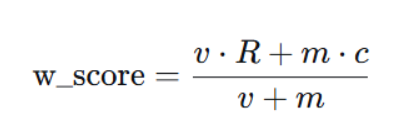

- v — количество оценок у конкретного фильма;
- R — средний рейтинг этого фильма;
- m — порог доверия (фильм должен иметь достаточно голосов, чтобы рейтинг считался надёжным);
- c — средний рейтинг по всем фильмам в системе.

In [12]:
v = popularite['count_rating']
R = popularite['avg_rating']
m = v.quantile(0.70)
c = R.mean()

popularite['w_score'] = ((v * R) + (m * c)) / (v + m)
popularite['count_rating'].describe()

count    250.000000
mean      28.416000
std       43.580546
min        1.000000
25%        5.000000
50%        7.000000
75%       11.000000
max      137.000000
Name: count_rating, dtype: float64

In [13]:
pop_sort = popularite.sort_values('w_score', ascending=False)
pop_sort.head(10)

,title,avg_rating,count_rating,w_score
4,Батя 2 Дед,8.571429,7,7.385954
5,Один дома 2 Затерянный в Нью Йорке,8.571429,7,7.385954
17,Мстители Война бесконечности,8.000000,9,7.240064
3,Послезавтра,8.600000,5,7.237414
2,Собачье сердце,8.600000,5,7.237414
9,Вызов,8.333333,6,7.222576
13,Линкольн для адвоката,8.000000,8,7.197845
20,9 рота,7.875000,8,7.142290
27,Лучшее предложение,7.636364,11,7.121963
6,Жмурки,8.500000,4,7.111515


C:\Users\Adil1\AppData\Local\Temp\ipykernel_17216\3681362374.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='w_score', y='title', data=top_10_movies, palette='Blues_r')


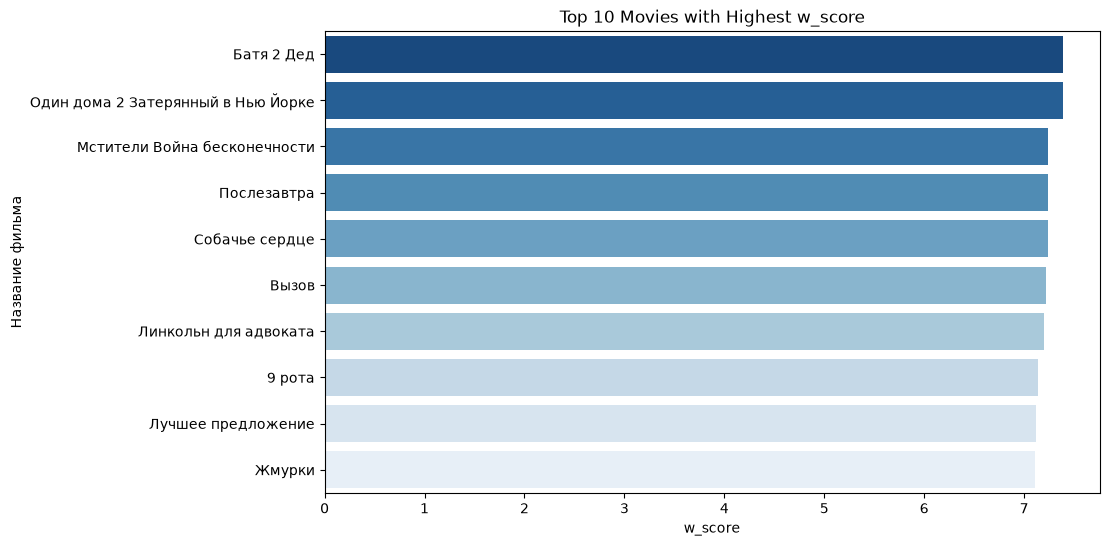

In [14]:
top_10_movies = pop_sort.head(10)
plt.figure(figsize=(10, 6))
sns.barplot(x='w_score', y='title', data=top_10_movies, palette='Blues_r')
plt.xlabel('w_score')
plt.ylabel('Название фильма')
plt.title('Top 10 Movies with Highest w_score')
plt.show()

## Рекомендательная система на основе коллаборативной фильтрации

Предлагает пользователям в качестве рекомендаций то, что часто смотрели вместе с просмотренными ими фильмами.

In [15]:
# Построение сводной матрицы пользователи-фильмы
users_pivot = df.pivot_table(index='user_id', columns='title', values='rating')
users_pivot.fillna(0, inplace=True)
users_pivot.head()

title,1 1,12 лет рабства,9 рота,Ford против Ferrari,Kingsman Секретная служба,Аватар,Август,Адвокат дьявола,Аквамен,Алиса в Стране чудес,...,Человек паук,Человек паук Вдали от дома,Человек паук Нет пути домой,Человек паук Новый день,Черный ящик,Шерлок Холмс,Шоу Трумана,Экипаж,Эффект бабочки,Я легенда
user_id,,,,,,,,,,,,,,,,,,,,,
1,9.0,0.0,0.0,0.0,0.0,7.0,3.0,0.0,4.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,7.0,0.0,0.0,0.0,0.0,8.0,3.0,0.0,0.0,0.0,...,0.0,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,4.0,7.0,0.0,0.0,0.0,...,0.0,0.0,10.0,0.0,0.0,0.0,4.0,0.0,0.0,0.0
5,6.5,0.0,0.0,0.0,0.0,8.5,9.0,0.0,0.0,0.0,...,8.0,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Коллаборативная фильтрация с использованием корреляции (corrwith)

In [16]:
def same_movies(movie, threshold=0.5):
    if movie not in users_pivot.columns:
        return f"Фильм '{movie}' не найден в матрице."
    users_vote_film = users_pivot[movie]
    similar_with = users_pivot.corrwith(users_vote_film)
    similar_with = pd.DataFrame(similar_with, columns=['correlation'])
    similar_with.dropna(inplace=True)
    similar_with = similar_with[similar_with.index != movie]
    top_similar = similar_with.sort_values('correlation', ascending=False).head(10)
    filtered = top_similar[top_similar['correlation'] > threshold]
    return filtered if not filtered.empty else top_similar

test_movie = users_pivot.columns[0]
print(f"Похожие фильмы для '{test_movie}':")
same_movies(test_movie)

Похожие фильмы для '1 1':


,correlation
title,
Интерстеллар,0.359238
Брат,0.326751
Всё везде и сразу,0.269435
Гарри Поттер и Принц полукровка,0.250152
Коммерсант,0.238435
Загадочная история Бенджамина Баттона,0.220738
Матрица,0.219851
Джокер,0.218737
Пчеловод,0.211387


## Коллаборативная фильтрация: модель NearestNeighbors из scikit-learn

Используем k-NN с косинусной метрикой для эффективного расчёта сходства.

In [17]:
movie_df_matrix = csr_matrix(users_pivot.values).T
model_knn = NearestNeighbors(metric='cosine', algorithm='brute')
model_knn.fit(movie_df_matrix)

def find_similar_movies(movie_name, num_neighbors=10):
    if movie_name not in users_pivot.columns:
        return f"Фильм '{movie_name}' не найден."
    movie_index = users_pivot.T.index.get_loc(movie_name)
    movie_vector = movie_df_matrix[movie_index]
    distances, indices = model_knn.kneighbors(movie_vector, n_neighbors=num_neighbors + 1)
    
    similar_indices = indices[0][1:]
    similar_distances = distances[0][1:]
    list_similar = users_pivot.T.index[similar_indices].tolist()
    
    return pd.DataFrame({
        'Movie': list_similar,
        'Distance': similar_distances
    })

find_similar_movies(test_movie)

,Movie,Distance
0,Интерстеллар,0.136694
1,Коммерсант,0.144813
2,Брат,0.147218
3,Гарри Поттер и философский камень,0.154539
4,Бойцовский клуб,0.157458
5,Пчеловод,0.164278
6,Субстанция,0.168254
7,Титаник,0.173552
8,Кракен,0.181664
9,Достать ножи,0.182647


### Поиск любимых фильмов пользователя

In [18]:
def find_favorite_movies(user_id, num_movies=10):
    user_ratings = users_pivot.loc[user_id]
    top_movies = user_ratings.sort_values(ascending=False).head(num_movies)
    return pd.DataFrame({
        'favorite movies': top_movies.index,
        'rating': top_movies.values
    })

user_test_id = users_pivot.index[0]
find_favorite_movies(user_test_id)

,favorite movies,rating
0,Движение вверх,10.0
1,Леон,10.0
2,Титаник,10.0
3,Основатель,10.0
4,Лучшее предложение,10.0
5,Интерстеллар,9.5
6,Гарри Поттер и философский камень,9.0
7,День курка,9.0
8,1 1,9.0
9,Риддик,9.0


### Персональные рекомендации для пользователя
Находим похожих пользователей и рассчитываем взвешенный балл для непросмотренных фильмов.

In [19]:
user_item_matrix = csr_matrix(users_pivot.values)
model_user_knn = NearestNeighbors(metric='cosine', algorithm='brute')
model_user_knn.fit(user_item_matrix)

def find_user_recommendations(user_id, num_neighbors=20, num_movies=10):
    user_index = users_pivot.index.get_loc(user_id)
    
    distances, indices = model_user_knn.kneighbors(
        user_item_matrix[user_index],
        n_neighbors=num_neighbors + 1
    )
    similar_user_indices = indices[0][1:]
    similar_distances = distances[0][1:]
    
    similar_ratings = users_pivot.iloc[similar_user_indices]
    weights = 1 / (similar_distances + 1e-9)
    weighted_scores = similar_ratings.T.dot(weights) / weights.sum()
    
    target_ratings = users_pivot.iloc[user_index]
    unseen = target_ratings[target_ratings == 0].index
    candidates = weighted_scores.loc[unseen]
    
    top_movies = candidates.sort_values(ascending=False).head(num_movies)
    return pd.DataFrame({
        'Recommended Movies': top_movies.index,
        'Score': top_movies.values.round(3)
    })

find_user_recommendations(user_test_id)

,Recommended Movies,Score
0,Начало,6.100
1,Батя,6.021
2,Паразиты,5.489
3,Холоп,5.193
4,Форрест Гамп,5.039
5,Брат 2,4.524
6,Джентльмены,4.420
7,Законопослушный гражданин,4.329
8,Пираты Карибского моря Проклятие Черной жемчужины,4.207
9,Батя 2 Дед,1.833


## Рекомендации на основе косинусного сходства

In [20]:
similarity_score = cosine_similarity(users_pivot.T)
print('Матрица сходства:', similarity_score.shape)

users_pivot2 = users_pivot.T

def recommend(movie_name):
    if movie_name not in users_pivot2.index:
        return f"Фильм '{movie_name}' не найден в базе рекомендаций."
    
    index = np.where(users_pivot2.index == movie_name)[0][0]
    similar_movies = sorted(list(enumerate(similarity_score[index])), key=lambda x: x[1], reverse=True)[1:9]
    
    data = []
    for i in similar_movies:
        title = users_pivot2.index[i[0]]
        score = i[1]
        temp_df = movies[movies['title'] == title]
        if not temp_df.empty:
            genres = temp_df['genres'].values[0]
            poster = temp_df['poster_url'].values[0]
            data.append({
                'Movie-Title': title,
                'Genres': genres,
                'Poster-URL': poster,
                'Similarity Score': round(score, 6)
            })
    return pd.DataFrame(data)

recommend(test_movie)

Матрица сходства: (250, 250)


,Movie-Title,Genres,Poster-URL,Similarity Score
0,Интерстеллар,"фантастика, драма, приключения",https://cdnrrviubnyuntopbez5.svc.cdn.yandex.ne...,0.863306
1,Коммерсант,драма,https://cdnrrviubnyuntopbez5.svc.cdn.yandex.ne...,0.855187
2,Брат,"драма, криминал, боевик",https://cdnrrviubnyuntopbez5.svc.cdn.yandex.ne...,0.852782
3,Гарри Поттер и философский камень,"фэнтези, приключения, семейный",https://cdnrrviubnyuntopbez5.svc.cdn.yandex.ne...,0.845461
4,Бойцовский клуб,"триллер, драма, криминал",https://cdnrrviubnyuntopbez5.svc.cdn.yandex.ne...,0.842542
5,Пчеловод,"боевик, криминал",https://cdnrrviubnyuntopbez5.svc.cdn.yandex.ne...,0.835722
6,Субстанция,"ужасы, драма",https://cdnrrviubnyuntopbez5.svc.cdn.yandex.ne...,0.831746
7,Титаник,"мелодрама, триллер, драма",https://cdnrrviubnyuntopbez5.svc.cdn.yandex.ne...,0.826448
